# Exercise 4
**Veikka Immonen**

In [328]:
import numpy as np
import scipy as sci
import scipy.sparse as sp
from scipy.special import gammaln
from sksparse.cholmod import cholesky

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel, Product

from collections.abc import Iterable
from itertools import product
from tqdm import tqdm

import matplotlib.pyplot as plt

## Continuation of GP regression from previous exercises

### Generate the data from the underlying true process

Data is from a model

$$
y = Hx + \epsilon
$$

* $\theta := (\nu, \ell, \sigma) = (2.5, 0.1, 1.0)$
* $x \sim \mathcal{GP}(0, c_\theta(x, x'))$
* $c_\theta(x, x') = \sigma^2 \frac{2^{1 - \nu}}{\Gamma(\nu)}\left(\sqrt{2\nu}\frac{||x - x'||}{\ell}\right)^\nu K_\nu\left(\sqrt{2\nu}\frac{||x - x'||}{\ell}\right)$
* $H$: select operator
* $\epsilon \sim \mathcal{N}(0, \sigma_\epsilon^2), ~ \sigma_\epsilon = 0.2$ 
* $n_\text{data} = 51$
* $n_\text{state} = 1001$

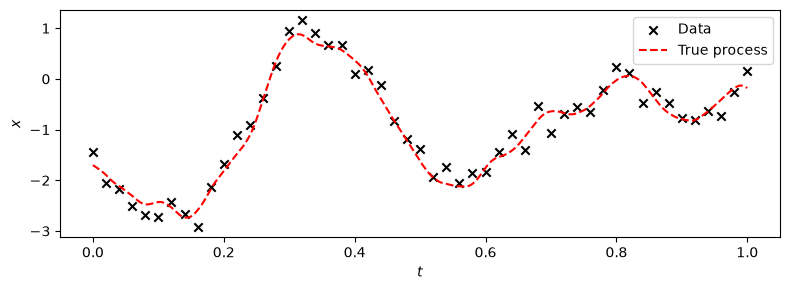

In [550]:
# true hyperparameters
nu_true = 2.5
ell_true = 0.1
scale_true = 1.0
sigma_true = 0.2

# sizes and the operator
n_data = 51
n_true = 1001
step = (n_true - 1) // (n_data - 1)
operator = lambda x: x[::step]

# grid composition
t_data = np.arange(n_data).reshape((-1, 1)) / (n_data - 1)
t_true = np.arange(n_true).reshape((-1, 1)) / (n_true - 1)

# initialize the process
kernel_true = Product(
    ConstantKernel(constant_value=scale_true**2, constant_value_bounds="fixed"),
    Matern(length_scale=ell_true, length_scale_bounds="fixed", nu=nu_true)
)
gp_true = GaussianProcessRegressor(kernel=kernel_true)

# realization and "observations"
np.random.seed(24)
y_true = gp_true.sample_y(t_true)
y_data = operator(y_true) + sigma_true * np.random.randn(*t_data.shape)

# plot
_, ax = plt.subplots(figsize=(8, 3))
ax.set_xlabel("$t$")
ax.set_ylabel("$x$")

ax.scatter(t_data, y_data, c="k", marker="x", label="Data")
ax.plot(t_true, y_true, 'r--', label="True process")
ax.legend()

plt.tight_layout()
plt.savefig("data_and_true.pdf")
plt.show()

### Sample $x$ and $\ell$

The full hierarchical model is
$$
p(x, \theta | y) \propto \underbrace{p(y | x, \theta)}_\text{likelihood} \underbrace{p(x | \theta)}_\text{prior} \underbrace{p(\theta)}_\text{hyperprior}
$$
Now we sample $x$ and $\ell$, hence:
$$
p(x, \ell | y) \propto p(y | x) p(x | \ell) p(\ell),
$$
Like previously same Metropolis-within-Gibbs (MWG) -like schema is used again.

### SPDE Approximation

For the approximation, let $\alpha = \nu + \frac{d}{2}, ~ d = \dim(t)$, and set distance scale $\kappa = \frac{\sqrt{2\nu}}{\ell}$ in the Matérn covariance. Now, the covariance is a solution to SPDE
$$
\begin{aligned}
\tau(\kappa^2 - \Delta)^\frac{\alpha}{2}\mathcal{X} &= \mathcal{W}, & \mathcal{W} &\sim \mathcal{N}(0, I),
\end{aligned}
$$
where
$$
\begin{aligned}
\tau^2 &= \frac{\Gamma(\nu)}{\Gamma(\alpha)(4\pi)^\frac{d}{4}\kappa^{2\nu}\sigma^2}, &
\Delta = \sum_{i=1}^d \frac{\partial^2}{\partial t_i^2}
\end{aligned}
$$
Approximation on a regular $d$-dimensional grid with spacing constants $h=\{h_1, ..., h_d\}$ using finite difference yields
$$
\begin{aligned}
\tau(\kappa^2 - L^{(h)})^\frac{\alpha}{2}x &= w, & w &\sim \mathcal{N}(0, \underbrace{\prod_{i=1}^d \frac{1}{h_i}}_{=\delta} I),
\end{aligned}
$$
where $L$ is a linear operator of second order central difference. Let $A^{(h)}:= \kappa I + L^{(h)}$. Now we get
$$
\begin{aligned}
x &\sim \mathcal{N}(0, Q^{-1}) & Q &= \delta\tau^2 A^\alpha
\end{aligned}
$$
While A is sparce and hence computationally easy to deal with, its inverse would be still dense. Also, $\alpha$ must be a positive integer. Therefore an alternative iterative sampling algorithm is used to prevent the computation of $Q^{-1}$:
1. $\xi \sim \mathcal{N}(0, I)$
2. if $\alpha$ is odd:
    - solve $L^T\tilde{x}_0 = \xi, ~ LL^T = A$
    - $n_\text{iters} = \frac{\alpha - 1}{2}$
3. otherwise:
    - solve $\tilde{x}_0 = \xi$
    - $n_\text{iters} = \frac{\alpha}{2}$
4. for $i = 1,...,n_\text{iters}$:
    - solve $A\tilde{x}_{i} = \tilde{x}_{i-1}$
5. $x = \frac{\tilde{x}_{n_\text{iters}}} {\tau \sqrt{\delta}}$

Moreover, the prior is also computed without constructing full $Q$. The full prior is
$$
p(x | \theta) \propto \exp\left(-\frac{1}{2}\left( x^TQx - \log |Q| + \frac{d}{2}\log2\pi \right) \right),
$$
where
* $x^TQx = \delta\tau^2 x^T\underbrace{A...A}_{\times \alpha} x$
* $\log |Q| = \log |\tau^2 \delta A^\alpha| = 2n\log\tau + n\log\delta + \alpha\log|A|$

In [560]:
def log_tau(d, nu, kappa, sigma):
    return (
        0.5 * (gammaln(nu) - gammaln(nu + d/2))
        - nu * np.log(kappa)
        - (d / 4) * np.log(4 * np.pi)
        - np.log(sigma)
    )


def build_laplacian_1d(n, step_inv, periodic=False):
    c = step_inv**2
    L = sp.diags(
        diagonals=[c , -2*c, c],
        offsets=[-1, 0, 1],
        shape=(n, n), format="lil"
    )
    if periodic:
        L[0, -1] = c
        L[-1, 0] = c
    else:
        # Homogeneous Neumann boundaries.
        L[0, 0] = -c
        L[-1, -1] = -c
    return L.tocsc()


def build_laplacian(shape, step_inv, periodic=None):

    assert isinstance(shape, Iterable)
    assert isinstance(step_inv, Iterable)
    assert len(shape) == len(step_inv)
    if periodic is None:
        periodic = (False,) * len(shape)
    assert isinstance(periodic, Iterable)
    assert len(periodic) == len(shape)

    out = None
    for i, (n, h_inv, p) in enumerate(zip(shape, step_inv, periodic)):
        L = build_laplacian_1d(n, h_inv, p)
        left = int(np.prod(shape[:i]))
        right = int(np.prod(shape[i+1:]))
        term = sp.kron(
            sp.kron(sp.eye(left, format="csc"), L),
            sp.eye(right, format="csc")
        )
        out = term if out is None else out + term

    return out


class MaternFDMSPDESampler:

    def __init__(self, boundaries, shape, periodic, nu, ell, sigma, pad=1):
        """
        FDM-based sampler for a Matérn Gaussian field using the SPDE formulation.

        Parameters
        ----------
        boundaries : tuple of pair of floats
            Boundaries of the regular grid
        shape : tuple
            Discretization size of each axis
        periodic : tuple
            Tuple of booleans indicating wether the grid is periodic or not
        nu : float
            Matérn smoothness parameter. Must satisfy
            nu + d/2 ∈ {1, 2, 3, ...}.
        ell : float
            Matérn length scale.
        sigma : float
            Marginal standard deviation.
        pas : int
            Size of extension beyond boundary, if axis is non-periodic

        Notes
        -----
        The created matrices are shared by cloned samplers and are therefore
        treated as read-only. Modifying either matrix after initialization may
        invalidate cached quantities, its factorization, and log(det(K)).
        """

        self.d = len(boundaries)
        alpha_float = nu + self.d / 2
        alpha = round(alpha_float)

        self.boundaries = tuple(map(tuple, boundaries))
        self.shape = tuple(shape)
        self.periodic = tuple(map(bool, periodic))
        self.pad = pad
        self.shape_extended = tuple(
            n if p else n + 2 * self.pad
            for n, p in zip(self.shape, self.periodic)
        )
        self.step_inv = np.array([
            (n - 1 if not p else n) / (b - a)
            for (a, b), n, p in zip(self.boundaries, self.shape, self.periodic)
        ])
        self.slices = tuple(
            slice(None) if p else slice(pad, -pad) if pad > 0 else slice(None)
            for p in self.periodic
        )

        self.n = np.prod(self.shape_extended)
        self.vol_sqrt = np.sqrt(np.prod(1.0 / self.step_inv))
        self.nu = nu
        self.ell = ell
        self.sigma = sigma
        self.kappa = np.sqrt(2 * self.nu) / self.ell
        self.alpha = alpha

        self.L = build_laplacian(self.shape_extended, self.step_inv, self.periodic)
        self.A = self.kappa**2 * sp.eye(self.n, format="csc") - self.L
        self.solve_A = sp.linalg.factorized(self.A)
        self.L_A, self.p_A = cholesky(self.A, lower=True)
        self.pinv_A = np.argsort(self.p_A)
        self.logdet_A = 2.0 * np.log(self.L_A.diagonal()).sum()

        self.tau = np.exp(log_tau(self.d, self.nu, self.kappa, self.sigma))


    def __call__(self, n_samples=1, extended=False):
        """
        Samples Matérn field(s).

        Parameters
        ----------
        n_samples : 
            Number of field realization(s).

        Returns
        -------
        ndarray, shape (n,), if n_samples==1, otherwise (n_samples, n)
        """

        z = np.random.randn(self.n, n_samples)
        if self.alpha % 2 == 1:
            z = z[self.p_A, :]
            w = sp.linalg.spsolve_triangular(self.L_A.T, z, lower=False)
            w = w[self.pinv_A, :]
        else:
            w = z

        for _ in range(self.alpha // 2):
            w = self.solve_A(w)

        w = w.T.reshape((n_samples, *self.shape_extended))
        if not extended:
            w = w[(slice(None), *self.slices)]
        if n_samples == 1:
            w = w[0]

        return w / (self.tau * self.vol_sqrt)


    def logpdf(self, x):
        """
        Evaluate the log-density of the Matérn field.

        Parameters
        ----------
        x : ndarray, of shape_extended or (n_samples, *shape_extended)
            Field realization(s).

        Returns
        -------
        float or ndarray
            Log-density for each realization.
        """

        if x.ndim == len(self.shape):
            assert x.shape == self.shape_extended
            x = x.ravel().reshape((1, -1))
            scalar = True
        elif x.ndim == len(self.shape) + 1:
            assert x.shape[1:] == self.shape_extended
            x = x.reshape((x.shape[0], -1))
            scalar = False
        else:
            raise ValueError("x must have shape shape_extended or (n_samples, *shape_extended)")
        x = x.T

        qx = x
        for _ in range(self.alpha):
            qx = self.A @ qx

        quad = self.tau**2 * self.vol_sqrt**2 * np.sum(x * qx, axis=0)

        logdet_Q = (
            2.0 * self.n * (np.log(self.tau) + np.log(self.vol_sqrt))
            + self.alpha * self.logdet_A
        )

        logp = (
            0.5 * logdet_Q - 0.5 * quad
            - 0.5 * self.n * np.log(2.0 * np.pi)
        )

        return logp[0] if scalar else logp



    def clone(self, *, nu=None, ell=None, sigma=None):
        """
        Create a soft copy of the sampler with optionally modified parameters.

        Parameters
        ----------
        nu : float or None, optional
        ell : float or None, optional
        sigma : float or None, optional

        If a parameter is None, the current value from the original class is retained.

        Returns
        -------
        MaternSPDESampler
            A new sampler instance with the requested parameter values.

        Notes
        -----
        This is a soft copy rather than a deep copy. matrices 
        are intentionally shared between the original and cloned samplers.

        If ell is unchanged, the expensive A-dependent state is also shared:
        K, its Cholesky factorization, permutation, solver, and log-determinant.
        If ell changes, these quantities are recomputed for the new A.

        The shared matrices and cached arrays are therefore assumed to be
        read-only after construction.
        """

        new = object.__new__(type(self))

        new.d = self.d
        new.boundaries = self.boundaries
        new.shape = self.shape
        new.periodic = self.periodic
        new.pad = self.pad
        new.shape_extended = self.shape_extended
        new.step_inv = self.step_inv
        new.slices = self.slices

        new.nu = self.nu if nu is None else nu
        new.ell = self.ell if ell is None else ell
        new.sigma = self.sigma if sigma is None else sigma
        new.kappa = np.sqrt(2 * new.nu) / new.ell
        new.tau = np.exp(log_tau(new.d, new.nu, new.kappa, new.sigma))

        new.n = self.n 
        new.vol_sqrt = self.vol_sqrt
        new.L = self.L

        alpha_float = new.nu + new.d / 2
        alpha = round(alpha_float)
        assert np.isclose(alpha_float, alpha) and alpha >= 1, (
            "alpha = nu + d/2 must be an integer >= 1"
        )
        new.alpha = alpha

        if ell is None:
            new.A = self.A
            new.L_A = self.L_A
            new.p_A = self.p_A
            new.pinv_A = self.pinv_A
            new.solve_A = self.solve_A
            new.logdet_A = self.logdet_A
        else:
            new.A = new.kappa**2 * sp.eye(new.n, format="csc") - new.L
            new.solve_A = sp.linalg.factorized(new.A)
            new.L_A, new.p_A = cholesky(new.A, lower=True)
            new.pinv_A = np.argsort(new.p_A)
            new.logdet_A = 2.0 * np.log(new.L_A.diagonal()).sum()
        return new


### From previous exercise

In [508]:
def sample_gp_full(t, y, model_state, model_param,
              init_state, init_param, beta_state, beta_param,
              ll_pcn, lp_mh, chain_length):

    """
    t: state grid
    y: data
    model_state: mapping from sampled state to data
    model_param: mapping from sampled param to true form
    init_state: state initialization
    init_param: parameter initialization: (nu, ell, scale, sigma)
    beta_state: random walk step size in state sampling
    beta_param: random walk step size in param sampling
    ll_pcn: log-likelihood function for the pcn proposal
    lp_mh: log-posterior function for the mh proposal
    chain_length: length of the chain
    """

    chain_state = []
    chain_param = []

    # old samples
    state_old = init_state.copy()
    param_old = init_param.copy()
    L_old = init_zero_mean_gp(t, model_param(param_old))
    ll_state_old = ll_pcn(y, state_old, param_old, model_state, model_param)
    lp_param_old = lp_mh(y, state_old, param_old, L_old, model_state, model_param)

    # initialize new samples
    state_new = None
    param_new = None
    L_new = None
    ll_state_new = None
    lp_param_new = None

    # Misc
    alpha_state = (1 - beta_state**2)**.5
    fixed_kernel = np.all(beta_param[:3] == 0)

    for _ in tqdm(range(chain_length)):

        # sample state
        w = np.random.randn(*state_old.shape)
        state_new = alpha_state * state_old + beta_state * L_old @ w
        ll_state_new = ll_pcn(y, state_new, param_old, model_state, model_param)
        if np.log(np.random.rand()) <= min(ll_state_new - ll_state_old, 0):
            state_old = state_new
            ll_state_old = ll_state_new
            lp_param_old = lp_mh(y, state_old, param_old, L_old, model_state, model_param)

        # sample param
        w = np.random.randn(*param_old.shape)
        param_new = param_old + beta_param * w
        if not fixed_kernel:
            L_new = init_zero_mean_gp(t, model_param(param_new))
        lp_param_new = lp_mh(y, state_old, param_new, L_new, model_state, model_param)
        if np.log(np.random.rand()) <= min(lp_param_new - lp_param_old, 0):
            param_old = param_new
            if not fixed_kernel:
                L_old = L_new
            lp_param_old = lp_param_new

        # add to chain
        chain_state.append(state_old.ravel())
        chain_param.append(param_old)

    return tuple(map(np.asarray, (chain_state, chain_param)))


def init_zero_mean_gp(t, param):
    kernel = Product(
        ConstantKernel(constant_value=param[2]**2),
        Matern(length_scale=param[1], nu=param[0])
    )
    L = np.linalg.cholesky(kernel(t))
    return L


def fit_linear(X, y):
    X = np.pad(X, ((0, 0), (0, 1)), constant_values=1)
    b = np.linalg.solve(X.T @ X, X.T @ y)
    return b


def plot_results(t_true, y_true, t_data, y_data,
                 chain_state, chain_param, model_param,
                 tail_size, bins=100):

    # plot state
    mu_state = chain_state[-tail_size:].mean(0)
    std_state = chain_state[-tail_size:].std(0)
    RMSE = np.sqrt(np.mean((mu_state - y_true.ravel())**2))

    fig_state, ax_state = plt.subplots(figsize=(8, 3))
    ax_state.set_title(f"{RMSE = :.3f}")
    ax_state.set_xlabel("$t$")
    ax_state.set_ylabel("$x$")
    ax_state.scatter(t_data, y_data, c="k", marker="x", label="Data")
    ax_state.plot(t_true, y_true, 'r--', label="True process")
    ax_state.plot(t_true, mu_state, 'b--', label="Estimated process")
    ax_state.fill_between(t_true.ravel(), mu_state - 1.96*std_state,
                          mu_state + 1.96*std_state, alpha=0.5,
                          color='gray', edgecolor=None,
                          label="Credible interval (95%)")
    ax_state.legend()

    theta = np.apply_along_axis(model_param, 1, chain_param)

    # plot param chain
    fig_pchain, ax_pchain = plt.subplots(figsize=(8, 3))
    ax_pchain.set_xlabel("# sample")
    ax_pchain.set_ylabel("$\\theta$ value")
    names = ["$\\nu$", "$\\ell$", "$\\sigma$", "$\\sigma_\\epsilon^2$"]
    ax_pchain.plot(theta)
    ax_pchain.legend(names)

    # plot param hists
    title=""
    fig_phist, ax_phist = plt.subplots(figsize=(8, 3))
    ax_phist.set_xlabel("$\\theta$")
    ax_phist.set_ylabel("probability density")
    for name, chain in zip(names, theta.T):
        tail = chain[-tail_size:]
        ax_phist.hist(tail, bins=bins, density=True,
                      stacked=True, label=name)
        title += f"$\\mathbb{{E}}(${name}$) = {tail.mean():.3f}$, "
    ax_phist.set_title(title[:-2])
    ax_phist.set_ylim(0, bins+bins//10)
    ax_phist.legend()

    return (fig_state, ax_state), (fig_pchain, ax_pchain), (fig_phist, ax_phist)

### Arrangements

* $(\nu_0, \ell_0, \sigma_0, \sigma_{\epsilon0}) = (2.5, 0.1, 1.0, 0.2)$
* $\beta_x = \beta_\ell = 0.1$
* log-Gaussian hyperprior: $\log\ell \sim \mathcal{N}(\log 0.2, 1.0^2)$
* $\text{Chain length} = 10000$

### Sample with full covariance

100%|██████████| 10000/10000 [00:49<00:00, 202.10it/s]


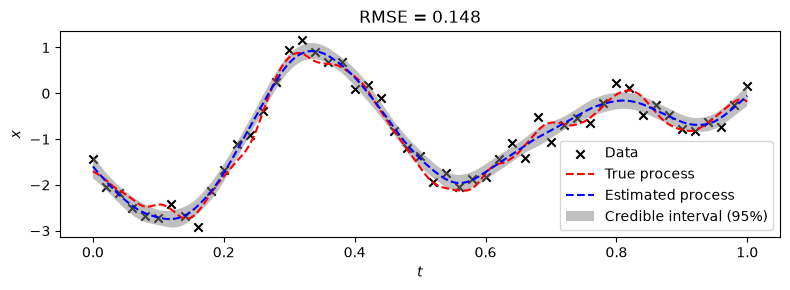

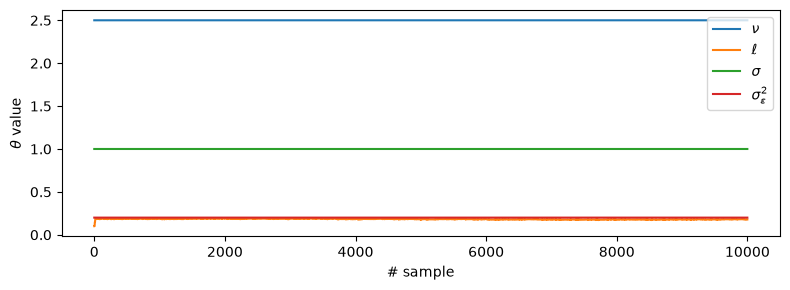

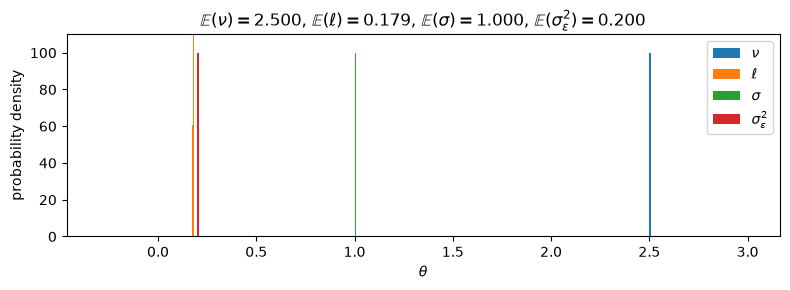

In [568]:
# models to transform state and data
model_state = operator
model_param = lambda x: np.exp(x)

# initial values, linear fit as a initial state,
# kernel parameters stay fixed
coeff = fit_linear(t_data, y_data).ravel()
init_state = t_true * coeff[0] + coeff[1]
init_param = np.log([2.5, 0.1, 1.0, 0.2])

# betas
beta_state = 1e-1
beta_param = np.array([0.0, 1e-1, 0.0, 0.0])


# log-likelihood
def log_likelihood(y, state, param, model_state, model_param):
    std_noise = model_param(param[-1])
    pred = model_state(state)
    return -0.5 * std_noise**(-2) * np.sum((y - pred)**2)


# log-posterior
def log_posterior(y, state, param, L, model_state, model_param):
    mu_log_ell = np.log(0.2)
    sigma_log_ell = 1.0

    _, log_ell, _, _ = param
    z = sci.linalg.solve_triangular(L, state, lower=True)
    dot = np.sum(z**2)
    logdet = 2.0 * np.sum(np.log(np.diag(L)))

    ll = log_likelihood(y, state, param, model_state, model_param)
    log_hyp_prior = -0.5 * ((mu_log_ell - log_ell) / (2 * sigma_log_ell))**2

    return ll + log_hyp_prior - 0.5 * (dot + logdet)


# sample
chain_length = 10_000
chain_state, chain_param = sample_gp_full(
    t_true, y_data,
    model_state, model_param,
    init_state, init_param,
    beta_state, beta_param,
    log_likelihood, log_posterior,
    chain_length
)

# plot results
(fig_state, ax_state), (fig_pchain, ax_pchain), (fig_phist, ax_phist) = \
    plot_results(t_true, y_true, t_data, y_data,
                 chain_state, chain_param,
                 model_param, chain_length//2)

fig_state.tight_layout()
fig_pchain.tight_layout()
fig_phist.tight_layout()

fig_state.savefig("1_1_1_state.pdf")
fig_pchain.savefig("1_1_1_pchain.pdf")
fig_phist.savefig("1_1_1_phist.pdf")

### Sample using SPDE covariance

In [567]:
def sample_gp_spde(t, y, model_state, model_param,
              init_state, init_param, beta_state, beta_param,
              ll_pcn, lp_mh, chain_length):

    """
    t: state grid
    y: data
    model_state: mapping from sampled state to data
    model_param: mapping from sampled param to true form
    init_state: state initialization
    init_param: parameter initialization: (nu, ell, scale, sigma)
    beta_state: random walk step size in state sampling
    beta_param: random walk step size in param sampling
    ll_pcn: log-likelihood function for the pcn proposal
    lp_mh: log-posterior function for the mh proposal
    chain_length: length of the chain
    """

    pad = 0
    chain_state = []
    chain_param = []

    # old samples
    state_old = np.pad(init_state, ((pad, pad), (0, 0)), mode="edge")
    param_old = init_param.copy()
    sampler_old = MaternFDMSPDESampler(((t[0], t[-1]),), (len(t),), (False,), *model_param(param_old)[:-1], pad=pad)
    ll_state_old = ll_pcn(y, state_old, param_old, sampler_old, model_state, model_param)
    lp_param_old = lp_mh(y, state_old, param_old, sampler_old, model_state, model_param)

    # initialize new samples
    state_new = None
    param_new = None
    sampler_new = None
    ll_state_new = None
    lp_param_new = None


    # Misc
    alpha_state = (1 - beta_state**2)**.5
    fixed_kernel = np.all(beta_param[:3] == 0)

    for _ in tqdm(range(chain_length)):

        # sample state
        sample = sampler_old(extended=True).reshape(state_old.shape)
        state_new = alpha_state * state_old + beta_state * sample
        ll_state_new = ll_pcn(y, state_new, param_old, sampler_old, model_state, model_param)
        if np.log(np.random.rand()) <= min(ll_state_new - ll_state_old, 0):
            state_old = state_new
            ll_state_old = ll_state_new
            lp_param_old = lp_mh(y, state_old, param_old, sampler_old, model_state, model_param)

        # sample param
        w = np.random.randn(*param_old.shape)
        param_new = param_old + beta_param * w
        if not fixed_kernel:
            nu, ell, sigma, _ = model_param(param_new)
            sampler_new = sampler_old.clone(nu=nu, ell=ell, sigma=sigma)
        lp_param_new = lp_mh(y, state_old, param_new, sampler_new, model_state, model_param)
        if np.log(np.random.rand()) <= min(lp_param_new - lp_param_old, 0):
            param_old = param_new
            if not fixed_kernel:
                sampler_old = sampler_new
            lp_param_old = lp_param_new

        # add to chain
        chain_state.append(state_old.ravel()[sampler_old.slices])
        chain_param.append(param_old)

    return tuple(map(np.asarray, (chain_state, chain_param)))


100%|██████████| 10000/10000 [00:04<00:00, 2184.37it/s]


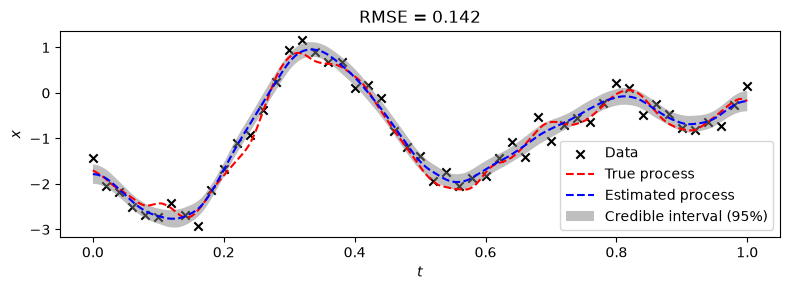

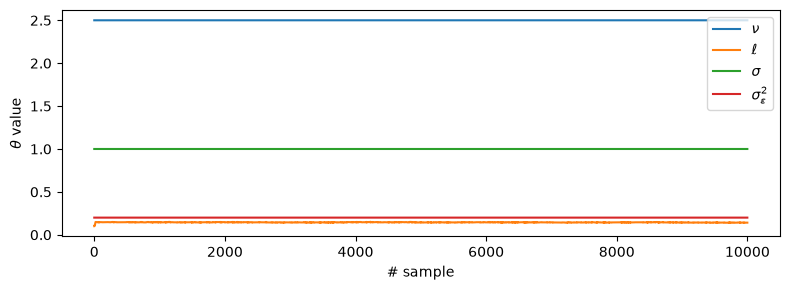

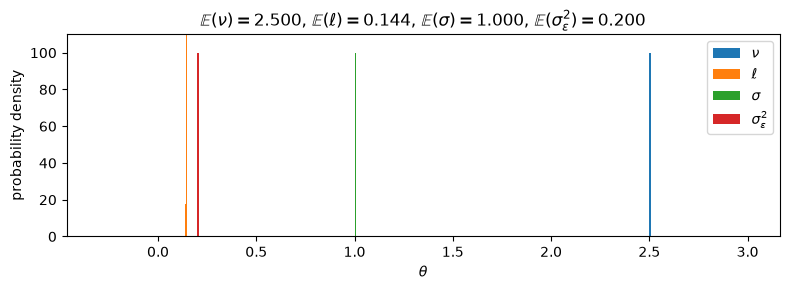

In [569]:
# models to transform state and data
model_state = operator
model_param = lambda x: np.exp(x)

# initial values, linear fit as a initial state,
# kernel parameters stay fixed
coeff = fit_linear(t_data, y_data).ravel()
init_state = t_true * coeff[0] + coeff[1]
init_param = np.log([2.5, 0.1, 1.0, 0.2])

# betas
beta_state = 1e-1
beta_param = np.array([0.0, 1e-1, 0.0, 0.0])


# log-likelihood
def log_likelihood(y, state, param, sampler, model_state, model_param):
    std_noise = model_param(param[-1])
    pred = model_state(state[sampler.slices])
    return -0.5 * std_noise**(-2) * np.sum((y - pred)**2)


# log-posterior
def log_posterior(y, state, param, sampler, model_state, model_param):
    mu_log_ell = np.log(0.2)
    sigma_log_ell = 1.0
    _, log_ell, _, _ = param

    log_like = log_likelihood(y, state, param, sampler, model_state, model_param)
    log_prior = sampler.logpdf(state.ravel())
    log_hyp_prior = -0.5 * ((mu_log_ell - log_ell) / (2 * sigma_log_ell))**2

    return log_like + log_prior + log_hyp_prior


# sample
chain_length = 10_000
chain_state, chain_param = sample_gp_spde(
    t_true, y_data,
    model_state, model_param,
    init_state, init_param,
    beta_state, beta_param,
    log_likelihood, log_posterior,
    chain_length
)

# plot results
(fig_state, ax_state), (fig_pchain, ax_pchain), (fig_phist, ax_phist) = \
    plot_results(t_true, y_true, t_data, y_data,
                 chain_state, chain_param,
                 model_param, chain_length//2)

fig_state.tight_layout()
fig_pchain.tight_layout()
fig_phist.tight_layout()

fig_state.savefig("1_1_2_state.pdf")
fig_pchain.savefig("1_1_2_pchain.pdf")
fig_phist.savefig("1_1_2_phist.pdf")